**Translasi Citra**

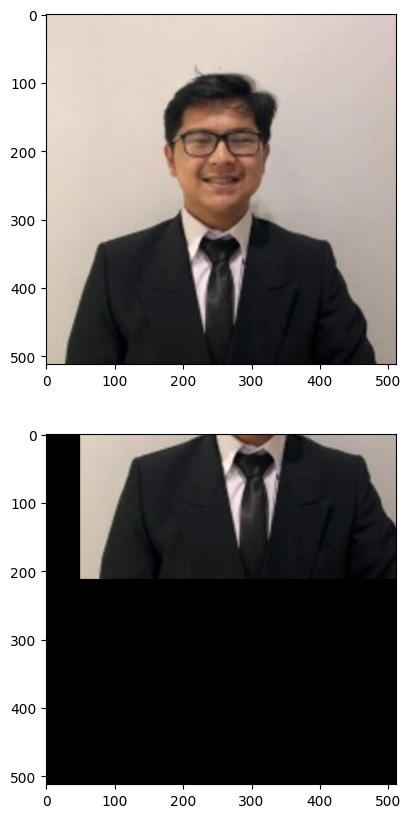

In [1]:
import imageio.v3 as img
import numpy as np
import matplotlib.pyplot as plt

def Translasi(image, shiftX, shiftY):

    imgTranslasi = np.roll(image, shift=shiftY, axis=0)  # Geser vertikal
    imgTranslasi = np.roll(imgTranslasi, shift=shiftX, axis=1)  # Geser horizontal

    # Mengisi bagian yang kosong dengan warna hitam (0)
    if shiftY > 0:
        imgTranslasi[:shiftY, :] = 0  # Bagian atas jika geser ke bawah
    elif shiftY < 0:
        imgTranslasi[shiftY:, :] = 0  # Bagian bawah jika geser ke atas
    if shiftX > 0:
        imgTranslasi[:, :shiftX] = 0  # Bagian kiri jika geser ke kanan
    elif shiftX < 0:
        imgTranslasi[:, shiftX:] = 0  # Bagian kanan jika geser ke kiri

    return imgTranslasi


image = img.imread("dani.jpg")

imgResult = Translasi(image, shiftX=50, shiftY=-300)

plt.figure(figsize=(10,10))
plt.subplot(2,1,1)
plt.imshow(image)
plt.subplot(2,1,2)
plt.imshow(imgResult)
plt.show()

**Mirroring**

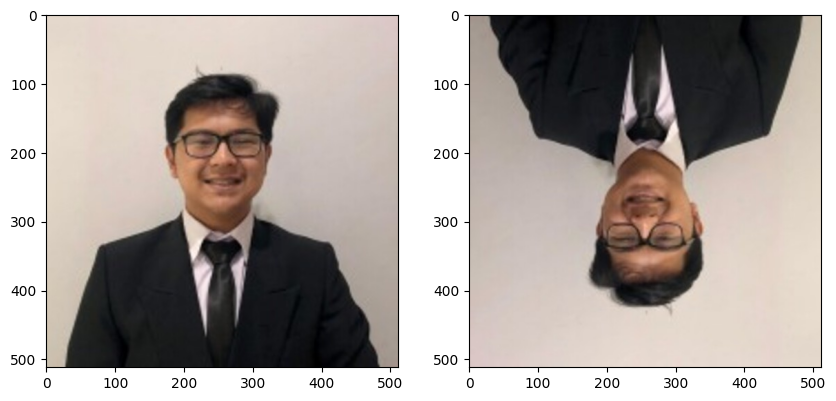

In [2]:
import numpy as np
import imageio.v2 as img
import matplotlib.pyplot as plt

image = img.imread('dani.jpg')

height, width = image.shape[:2]
both = np.zeros_like(image)

for y in range(height):
    for x in range(width):
        both[y, x] = image[height - 1 - y, width - 1 - x]

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)

plt.subplot(1, 2, 2)
plt.imshow(both)

plt.show()

**Rotasi Citra**

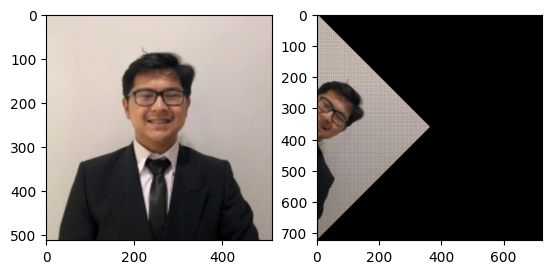

In [3]:
import numpy as np
import imageio.v2 as img
import matplotlib.pyplot as plt

def rotateImage(image, degree):
    radian_deg = np.radians(degree)
    cos_deg, sin_deg = np.cos(radian_deg), np.sin(radian_deg)

    height, width = image.shape[:2]
    max_dim = int(np.sqrt(height**2 + width**2))
    outputImage = np.zeros((max_dim, max_dim, 3), dtype=image.dtype)

    # pivot di (0,0): tanpa offset center
    for y in range(height):
        for x in range(width):
            newX = int(cos_deg * x - sin_deg * y)
            newY = int(sin_deg * x + cos_deg * y)

            if 0 <= newX < max_dim and 0 <= newY < max_dim:
                outputImage[newY, newX] = image[y, x]
    return outputImage

image = img.imread('dani.jpg')

rotated_image = rotateImage(image, 45)

plt.subplot(1, 2, 1)
plt.imshow(image)

plt.subplot(1, 2, 2)
plt.imshow(rotated_image)

plt.show()

**Zooming**

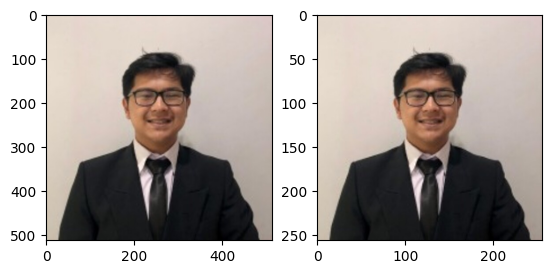

In [4]:
import numpy as np
import imageio.v2 as img
import matplotlib.pyplot as plt

def zoomMinus(image, factor):
    height, width = image.shape[:2]
    new_height = int(height / factor)
    new_width = int(width / factor)
    imgZoom = np.zeros((new_height, new_width, 3), dtype=image.dtype)

    for y in range(new_height):
        for x in range(new_width):
            ori_y = min(int(y * factor), height - 1)
            ori_x = min(int(x * factor), width - 1)
            imgZoom[y, x] = image[ori_y, ori_x]

    return imgZoom

image = img.imread('dani.jpg')
skala = 2.0

imgZoom = zoomMinus(image, skala)
img.imwrite("zoom_minus.jpg", imgZoom)

plt.subplot(1, 2, 1)
plt.imshow(image)

plt.subplot(1, 2, 2)
plt.imshow(imgZoom)

plt.show()